实验三 (2)

In [7]:
import numpy as np 
import networkx as nx
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成BA无标度网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_ba_scale_free_network(N, m):
    G = nx.barabasi_albert_graph(N, m)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 计算M^1矩阵
def calculate_M1_matrix(C, k, p):
    N = C.shape[0]
    M1 = np.zeros_like(C, dtype=float)
    for i in range(N):
        for j in range(N):
            delta_ij = 1 if i == j else 0
            term1 = (1 - p)**2 * delta_ij * k[j]
            term2 = p * (1 - p) * k[j] * (C[i, j] + C[j, i])
            term3 = p**2 * k[j] * np.dot(C[i, :], C[:, j])
            M1[i, j] = term1 + term2 + term3
    return M1

# 计算M^2矩阵
def calculate_M2_matrix(C, n, p):
    N = C.shape[0]
    M2 = np.zeros_like(C, dtype=float)
    for i in range(N):
        for j in range(N):
            delta_ij = 1 if i == j else 0
            term1 = (1 - p)**2 * delta_ij * n[j] 
            term2 = p * (1 - p) * n[j] * (C[i, j] + C[j, i]) 
            term3 = p**2 * n[j] * np.dot(C[i, :], C[:, j])
            M2[i, j] = term1 + term2 + term3
    return M2

# 计算 \beta_c
def calculate_beta_c(M, mu):
    eigenvalues = np.linalg.eigvals(M)  # 计算M矩阵的特征值
    eigenvalues = np.real(eigenvalues)  # 取特征值的实部，避免复数值
    lambda_max = np.max(eigenvalues)    # 找到最大特征值
    beta_c = mu / lambda_max  # 根据公式计算beta_c
    return beta_c


# 初始变量
N = 50
m = 5

mu = 0.1  # 恢复率
# p_move_values = np.arange(0, 1.05, 0.05)  # p_move从0到1，每隔0.1取一个值
p_move_values =np.concatenate([
    np.arange(0.01, 0.1, 0.01),
    np.arange(0.1, 1.01, 0.01)
])

alpha_values = [0.4, 0.5, 0.6]  # 不同的alpha值

# 方法一：生成BA无标度网络
W = generate_ba_scale_free_network(N, m)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成k和n的值
n = np.full(N, 100)  # 每个子种群规模
k_values = np.full(N, 100*0.1)  # 平均度

# 记录不同alpha和p_move值下的结果
all_results = {}

# 计算在不同 alpha 和 p_move 下的beta_c
for alpha in alpha_values:
    for p_move in p_move_values:
        # 计算M^1和M^2
        M1 = calculate_M1_matrix(C, k_values, p_move)
        M2 = calculate_M2_matrix(C, n, p_move)
        
        # 计算总的M矩阵
        M = alpha * M1 + (1 - alpha) * M2
        
        # 根据公式计算beta_c
        beta_c = calculate_beta_c(M, mu)
        all_results[(alpha, p_move)] = beta_c


import pandas as pd

# 初始化 DataFrame，行索引为alpha，列名为p_move_values
all_results_df = pd.DataFrame(index=alpha_values, columns=p_move_values)

# 将 all_results 的值填充到 DataFrame 中
for (alpha, p_move), beta_c in all_results.items():
    all_results_df.loc[alpha, p_move] = beta_c

# 保存为 CSV 文件
all_results_df.to_csv('all_results_matrix_1007.csv')



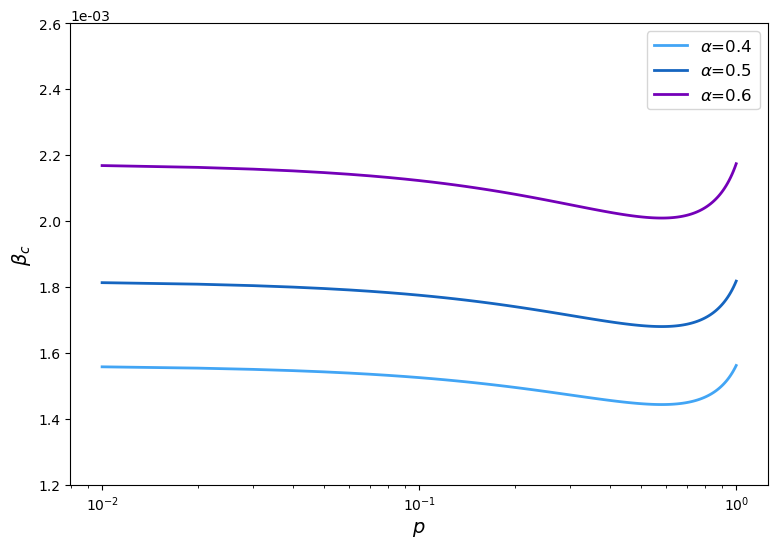

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import matplotlib.ticker as ticker

# 忽略FutureWarning
warnings.filterwarnings("ignore", category=FutureWarning)

# 读取CSV文件
all_results_df = pd.read_csv('all_results_matrix_1007.csv', index_col=0)

# 获取p_move_values和alpha_values
p_move_values = all_results_df.columns.astype(float)
alpha_values = all_results_df.index.astype(float)

# 绘制图表，分别为每个alpha值绘制曲线
plt.figure(figsize=(9, 6))

# 绘制alpha=0.4的曲线
sns.lineplot(x=p_move_values, y=all_results_df.loc[0.4]*1000, linewidth=2, markersize=5, color='#42a5f5',   
               label=r'$\alpha$=0.4') 
sns.lineplot(x=p_move_values, y=all_results_df.loc[0.5]*1000, linewidth=2, markersize=5, color='#1565c0',
             label=r'$\alpha$=0.5')
sns.lineplot(x=p_move_values, y=all_results_df.loc[0.6]*1000, linewidth=2, markersize=5, color='#7400b8',
             label=r'$\alpha$=0.6')

# 添加图表标签
plt.xlabel(r'$p$',fontsize='14')
plt.ylabel(r'$\beta_c$',fontsize='14')
# plt.title('Critical Beta vs. p_move for different alpha values')

plt.xscale("log")
plt.xticks([0.01, 0.1, 1], ["$10^{-2}$", "$10^{-1}$", "$10^{0}$"])

# # 自定义 y 轴格式化为数值部分
# def format_y_ticks(x, pos):
#     return f'{x:.1f}'  # 保留一位小数

# # 设置y轴为自定义格式
# plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(format_y_ticks))

# 设置y轴范围
plt.ylim(1.2, 2.6)

# 在 y 轴顶部添加统一的指数部分
plt.gca().text(-0.0, 1.0, '1e-03', fontsize=10, verticalalignment='bottom', transform=plt.gca().transAxes)

# 显示图例
plt.legend(fontsize='12')
plt.savefig('final_3b.pdf', dpi=300, bbox_inches='tight')
# 显示图表
plt.show()
